![Archive file 20, fixed sources v2](assets/archive-window/file-20.png)

# 20 · Projecting covered Steam activity into 2027

The provisional policy projects Action as the largest category in the covered cohort, followed by Strategy and RPG. Massively Multiplayer and Indie change places relative to the last-value reference, so their ordering depends on the modelling assumptions.

These projections use the fixed January 2026 cutoff and 519 games with complete histories. They estimate average concurrent activity for those games; future releases, unmatched games and the rest of the Steam market remain outside the target.

In [1]:
from pathlib import Path
import sys
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.project_fixed_cohort import run, POLICY, LABEL, REFERENCE
forecast = run(ROOT)

from src.notebook_display import present
from IPython.display import Image, display


![](assets/archive-window/section-divider.png)

## Provisional forecasting policy

Action and Massively Multiplayer retain last value because the smoothing alternatives offered small average gains or inconsistent cutoff results. Indie uses seasonal naive, while RPG and Strategy use damped seasonal smoothing following their stronger development comparisons. No further tuning was introduced.

Each selected model is fitted on the same 60 monthly observations from February 2021 through January 2026. The 23-month path runs from February 2026 to December 2027, and leads 12–23 supply the target year. The model routes and input fingerprints are saved so the policy can be reproduced.

In [2]:
present(pd.DataFrame(POLICY.items(), columns=["Category", "Selected model"]), "2027 projection review")


Category,Selected model
Action,Last value
Indie,Seasonal naive
Massively Multiplayer,Last value
RPG,Damped seasonal
Strategy,Damped seasonal


![](assets/archive-window/section-divider.png)

## Projected average activity during 2027

The annual summary averages the twelve monthly predictions, preserving the concurrent-activity measure. It estimates the typical level of activity across the year, with no interpretation as a count of distinct players. Categories overlap, so their values should be compared separately rather than added as a market total.

In [3]:
annual = forecast["annual_summary"]
selected = annual.loc[annual.policy.eq(LABEL)].sort_values("rank")
present(selected[["rank", "category", "model", "projected_mean_activity"]].assign(projected_mean_activity=lambda frame: frame.projected_mean_activity.map("{:,.0f}".format)).rename(
    columns={"rank":"Rank", "category":"Category", "model":"Model", "projected_mean_activity":"Projected mean concurrent activity · 2027"}
), "2027 projection review")


,Rank,Category,Model,Projected mean concurrent activity · 2027
Group,,,,
1,1,Action,Last value,"3,396,662"
9,2,Strategy,Damped seasonal,"1,174,261"
7,3,RPG,Damped seasonal,"849,199"
5,4,Massively Multiplayer,Last value,"800,468"
3,5,Indie,Seasonal naive,"772,780"


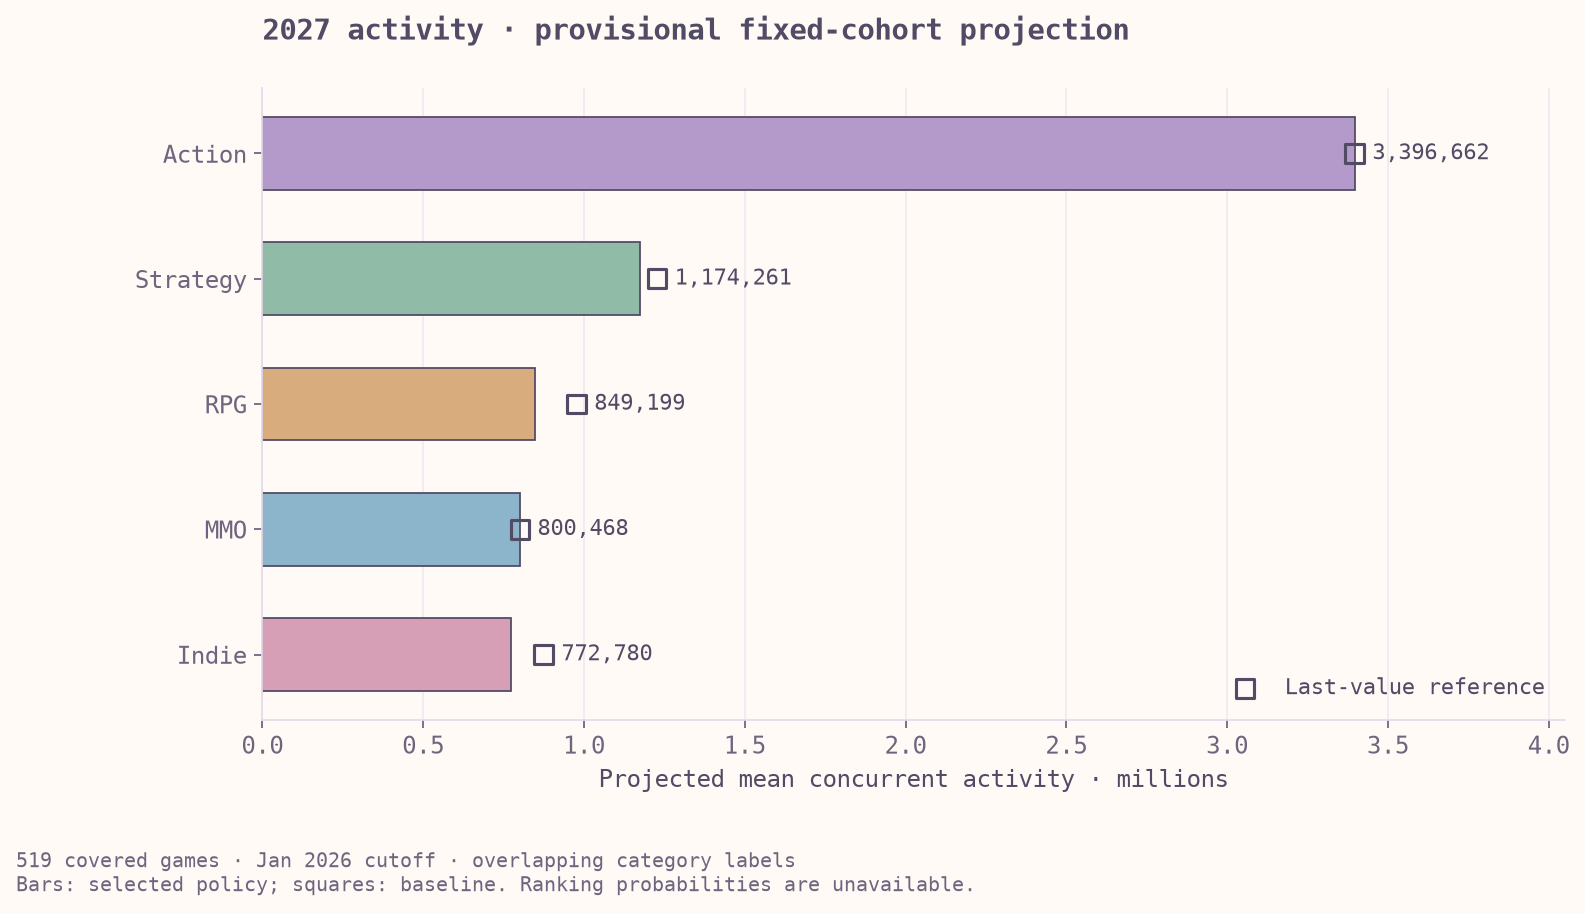

In [4]:
from src.portfolio_visuals import build
figure_paths = build(ROOT)
display(Image(filename=str(figure_paths["annual_comparison"])))


![](assets/archive-window/section-divider.png)

## Comparison with the January 2026 reference

The last-value reference repeats January 2026 activity throughout the forecast. Relative to that reference, the policy projects Indie 11.69% lower, RPG 13.08% lower and Strategy 4.29% lower. Action and Massively Multiplayer remain unchanged by construction.

These percentages compare two forecast approaches. They are separate from year-over-year growth estimates. Indie ranks above MMO under last value and below it under the provisional policy, which makes their ranking particularly sensitive to model choice.

In [5]:
present(forecast["baseline_comparison"].rename_axis(columns=None).round(2).rename(columns={
    "category":"Category", REFERENCE:"Last-value mean · 2027", LABEL:"Policy mean · 2027", "difference_pct":"Difference from reference (%)"
}), "2027 projection review")


Category,Last-value mean · 2027,Policy mean · 2027,Difference from reference (%)
Action,"3,396,661.79","3,396,661.79",0.00
Indie,"875,035.09","772,780.29",-11.69
Massively Multiplayer,"800,468.06","800,468.06",0.00
RPG,"976,982.89","849,198.84",-13.08
Strategy,"1,226,911.31","1,174,261.24",-4.29


![](assets/archive-window/section-divider.png)

## Historical-error sensitivity

For each selected model, the two historical target windows contain 24 forecast cases across 13 distinct calendar months. Repeated months are collapsed using the larger absolute error, then the 90th percentile supplies a descriptive error radius. Each 2027 monthly prediction is shown with that radius added and subtracted, with the lower value clipped at zero.

The errors come from dependent development folds used in model choice. Neither historical origin has earlier matured long-horizon errors available for a past-only calibration test. The ranges therefore have no validated predictive coverage, use the same radius at every target month, and may understate changes in future conditions. They provide a sensitivity view rather than an annual interval or a probability for the category rankings.

In [6]:
present(forecast["historical_error_radii"][["category", "radius", "forecast_cases", "unique_target_months"]].round(0).rename(
    columns={"category":"Category", "radius":"Historical error radius", "forecast_cases":"Development cases", "unique_target_months":"Distinct target months"}
), "2027 projection review")


Category,Historical error radius,Development cases,Distinct target months
Action,"198,152.00",24,13
Indie,"62,485.00",24,13
Massively Multiplayer,"105,412.00",24,13
RPG,"125,702.00",24,13
Strategy,"93,781.00",24,13


In [7]:
january = forecast["monthly_historical_error_ranges"].loc[lambda frame: frame.month.eq("2027-01-01")]
present(january[["category", "prediction", "historical_error_lower", "historical_error_upper"]].round(0).rename(
    columns={"category":"Category", "prediction":"January 2027 projection", "historical_error_lower":"Historical-error lower", "historical_error_upper":"Historical-error upper"}
), "2027 projection review")


Category,January 2027 projection,Historical-error lower,Historical-error upper
Action,"3,396,662.00","3,198,509.00","3,594,814.00"
Indie,"875,035.00","812,550.00","937,520.00"
Massively Multiplayer,"800,468.00","695,056.00","905,880.00"
RPG,"973,024.00","847,323.00","1,098,726.00"
Strategy,"1,242,014.00","1,148,232.00","1,335,795.00"


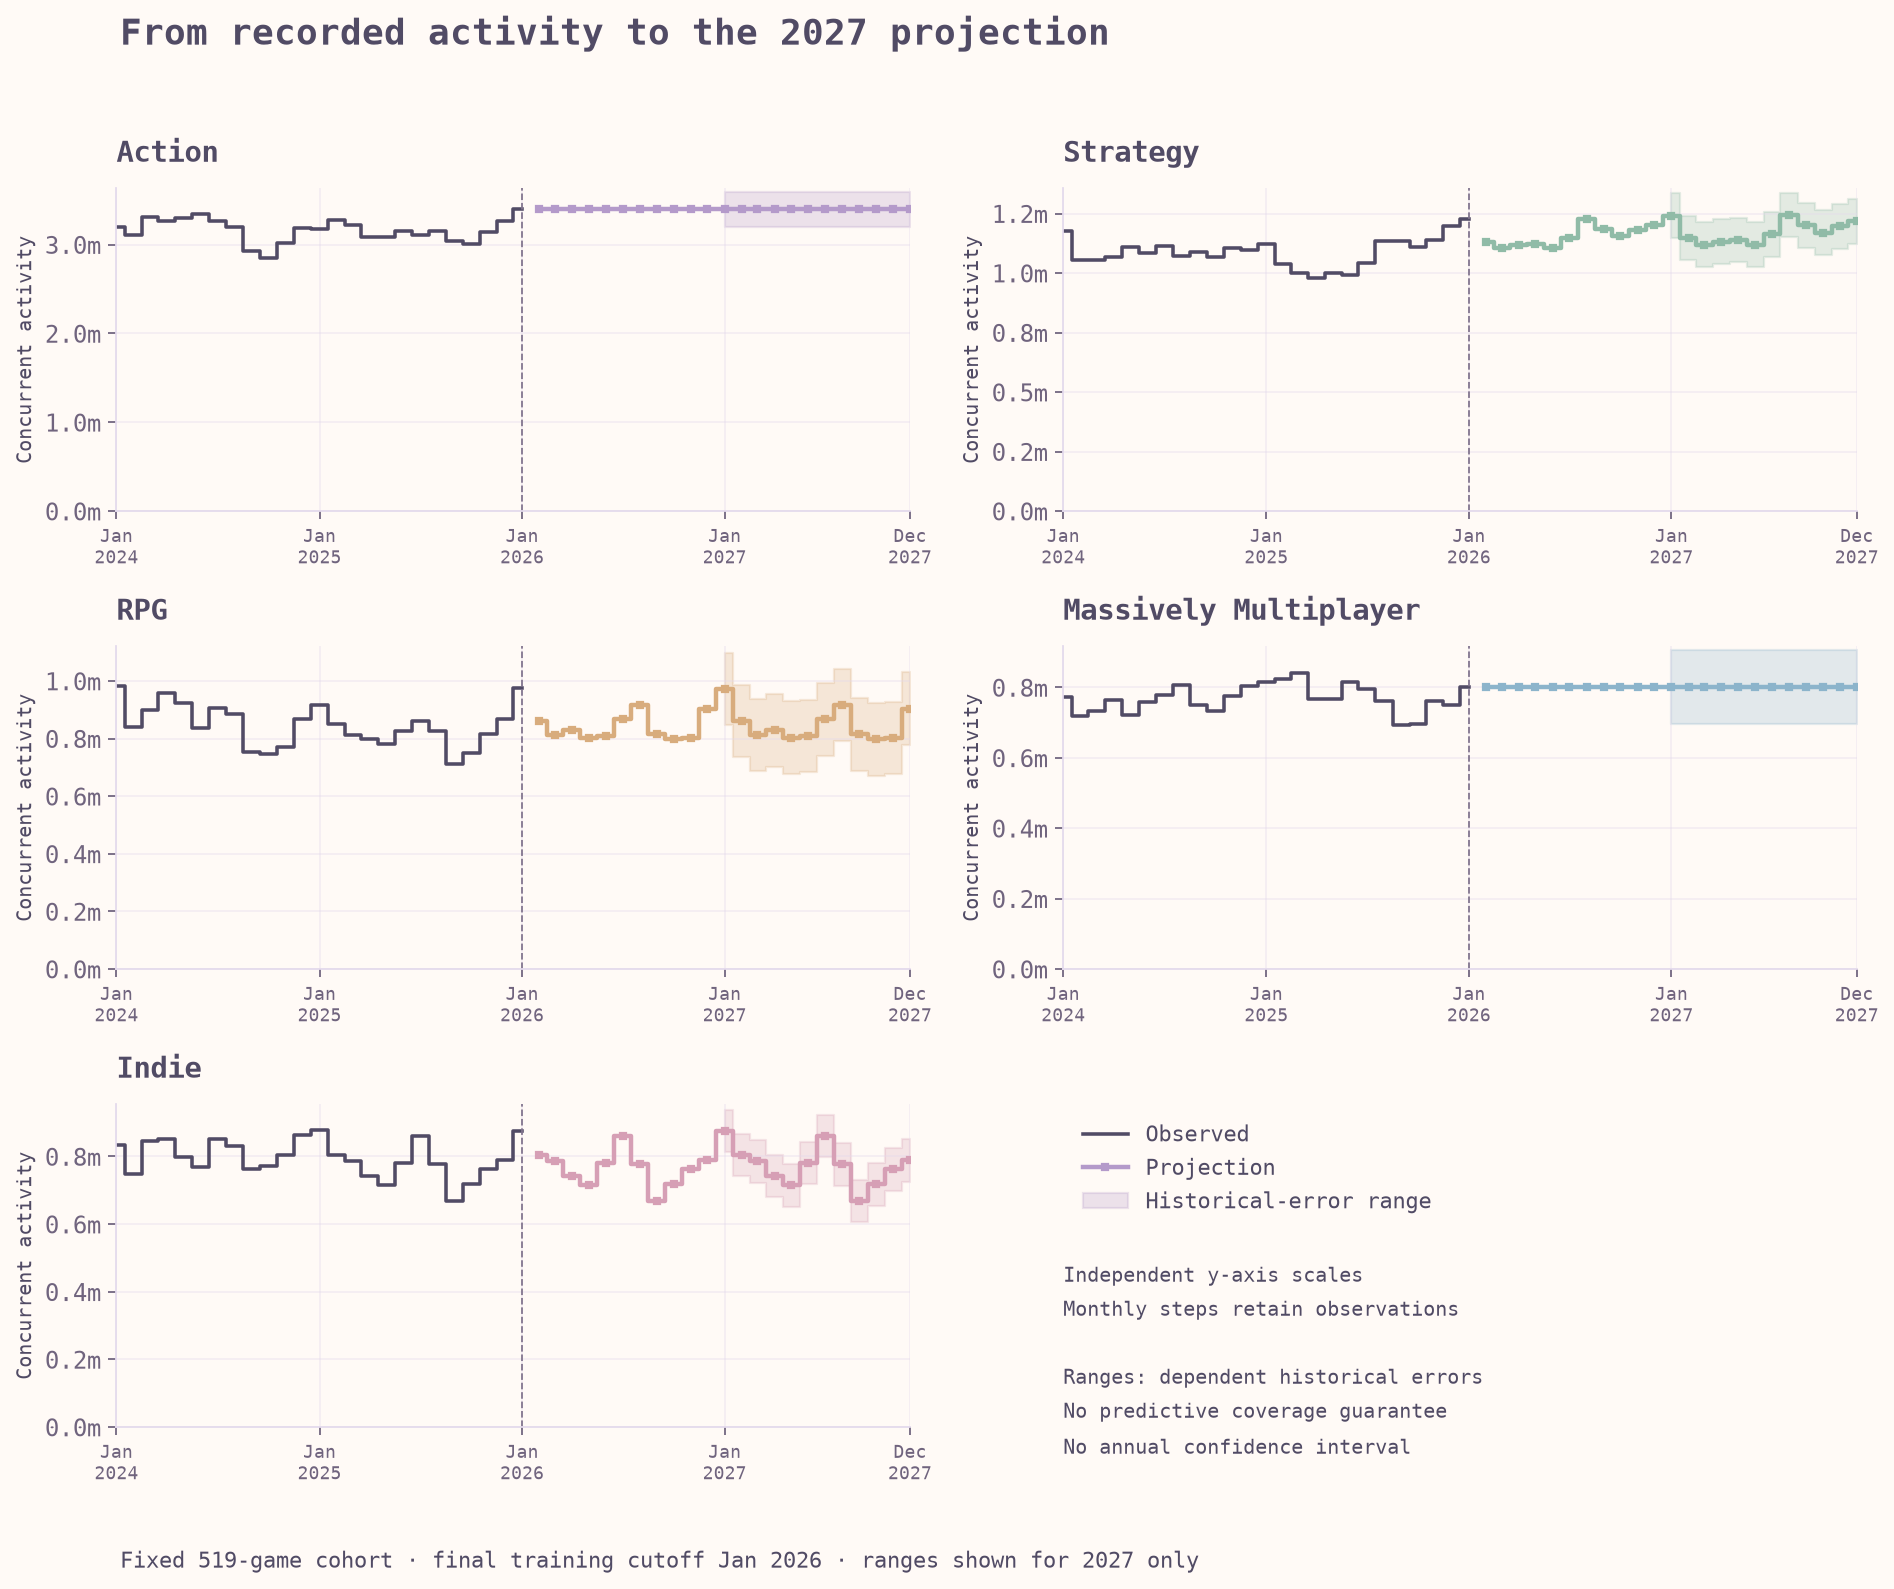

In [8]:
display(Image(filename=str(figure_paths["forecast_paths"])))


![](assets/archive-window/section-divider.png)

## Fit checks and interpretation

Both final smoothing fits converged, and no predictions required clipping. The forecast calendar contains twelve target-year predictions per category and policy, while the baseline and saved annual means reconcile with the monthly outputs.

The result supports a bounded portfolio conclusion: under the chosen policy, Action remains the largest source of recorded activity within this fixed cohort, while the exact levels and lower-category ordering depend on the model. Concentration in a few titles, retrospective cohort selection and limited validation remain important when presenting the findings. Earlier v1 forecasts use a different population and cutoff, so direct differences between versions cannot be interpreted as market growth.

In [9]:
fit_review = forecast["fit_diagnostics"].copy()
fit_review["converged"] = fit_review.converged.map({True:"Yes", False:"No"}).fillna("Not applicable")
fit_review["warnings"] = fit_review.warnings.fillna("Not applicable").replace("", "None")
present(fit_review.rename(columns={"category":"Category", "model":"Model", "training_months":"Training months", "clipped_predictions":"Clipped predictions", "converged":"Converged", "warnings":"Fit warnings"}), "2027 projection review")


Category,Model,Training months,Clipped predictions,Converged,Fit warnings
Action,Last value,60,0,Not applicable,Not applicable
Indie,Seasonal naive,60,0,Not applicable,Not applicable
Massively Multiplayer,Last value,60,0,Not applicable,Not applicable
RPG,Damped seasonal,60,0,Yes,None
Strategy,Damped seasonal,60,0,Yes,None


![](assets/archive-window/section-divider.png)

## Saved forecast artifacts

The provisional v2 policy, monthly projections, annual summary, baseline comparison and historical-error sensitivity are saved together with their fingerprints. The source roster remains fixed, and the original v1 forecast is preserved separately.

The [portfolio summary](../reports/PORTFOLIO_SUMMARY.md) brings together the result, method and remaining limitations.